# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [22]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [23]:
# Loading our cleaned dataset and checking its date range and structure
df = pd.read_csv('AviationData_Cleaned.csv', low_memory=False)
df['Event.Date'] = pd.to_datetime(df['Event.Date'], errors='coerce')

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df['Event.Date'].min().strftime('%Y-%m-%d')} to {df['Event.Date'].max().strftime('%Y-%m-%d')}")

# Previewing the file
display(df.head())
display(df.describe(include="all").T)

Dataset shape: (67694, 19)
Date range: 1983-01-01 to 2022-12-29


,Event.Date,Aircraft.damage,Aircraft.Category,Make,Model,Number.of.Engines,Engine.Type,Purpose.of.flight,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,total_occupants,serious_fatal_count,injury_fraction,aircraft_destroyed,Make.Model
0,1983-01-01,Substantial,NaN,Cessna,182P,1.0,Reciprocating,Personal,0.0,0.0,1.0,3.0,VMC,Approach,4.0,0.0,0.0,0.0,Cessna | 182P
1,1983-01-01,Substantial,NaN,Cessna,182RG,1.0,Reciprocating,Personal,0.0,0.0,0.0,2.0,VMC,Landing,2.0,0.0,0.0,0.0,Cessna | 182RG
2,1983-01-01,Substantial,NaN,Cessna,182P,1.0,Reciprocating,Personal,0.0,0.0,0.0,1.0,VMC,Takeoff,1.0,0.0,0.0,0.0,Cessna | 182P
3,1983-01-01,Substantial,NaN,Piper,PA-28R-200,1.0,Reciprocating,Personal,0.0,0.0,2.0,0.0,VMC,Approach,2.0,0.0,0.0,0.0,Piper | PA-28R-200
4,1983-01-01,Substantial,NaN,Cessna,140,1.0,Reciprocating,Instructional,0.0,0.0,0.0,2.0,VMC,Landing,2.0,0.0,0.0,0.0,Cessna | 140


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Event.Date,67694,NaN,NaN,NaN,1999-06-12 12:30:30.259698,1983-01-01 00:00:00,1989-06-07 06:00:00,1997-10-30 00:00:00,2008-05-04 00:00:00,2022-12-29 00:00:00,NaN
Aircraft.damage,66453,3,Substantial,51462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Aircraft.Category,20342,7,Airplane,17553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Make,67694,88,Cessna,25486,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,67694,5646,152,2218,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number.of.Engines,63800.0,NaN,NaN,NaN,1.129702,0.0,1.0,1.0,1.0,8.0,0.40125
Engine.Type,61803,6,Reciprocating,55023,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purpose.of.flight,59638,25,Personal,37198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total.Fatal.Injuries,67694.0,NaN,NaN,NaN,0.613156,0.0,0.0,0.0,0.0,349.0,5.573739
Total.Serious.Injuries,67694.0,NaN,NaN,NaN,0.246447,0.0,0.0,0.0,0.0,161.0,1.526689


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [24]:
# Grouping and separating the aircrafts by size based on total occupants
df['aircraft_size'] = np.where(df['total_occupants'] < 20, 'Small (<20 occupants)', 'Large (20+ occupants)')
df.loc[df['total_occupants'].isna() | (df['total_occupants'] == 0), 'aircraft_size'] = np.nan

print("Aircraft size group counts:")
display(df['aircraft_size'].value_counts(dropna=False).to_frame('records'))

Aircraft size group counts:


,records
aircraft_size,
Small (<20 occupants),66085
Large (20+ occupants),1233
NaN,376


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

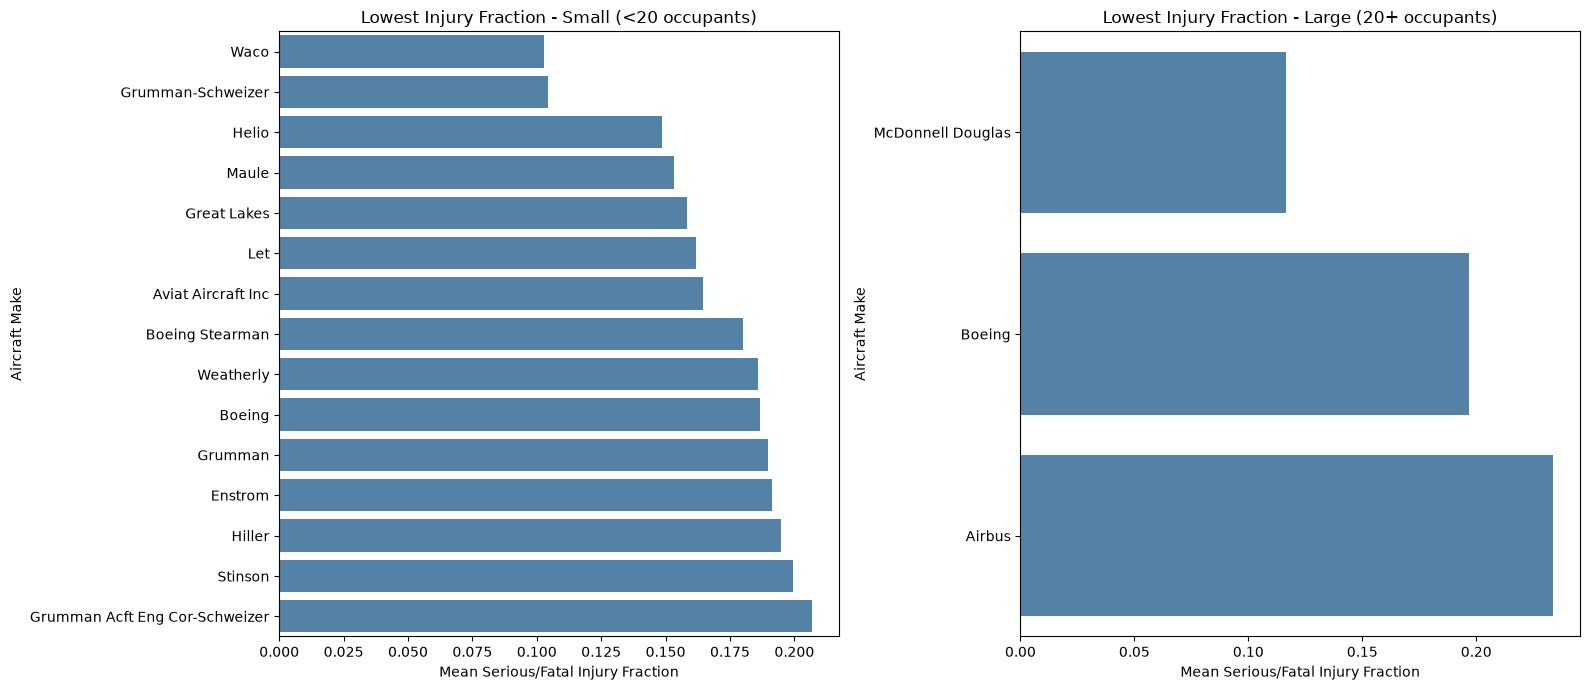

Summary table of top makes by lowest injury fraction:


,aircraft_size,Make,n,mean_injury_fraction,median_injury_fraction,destruction_fraction
15,Large (20+ occupants),McDonnell Douglas,107,0.116543,0.0,0.186916
5,Large (20+ occupants),Boeing,384,0.196626,0.0,0.218750
2,Large (20+ occupants),Airbus,71,0.233814,0.0,0.267606
105,Small (<20 occupants),Waco,138,0.102657,0.0,0.086957
63,Small (<20 occupants),Grumman-Schweizer,126,0.104497,0.0,0.253968
65,Small (<20 occupants),Helio,106,0.148728,0.0,0.122642
74,Small (<20 occupants),Maule,569,0.153281,0.0,0.094903
58,Small (<20 occupants),Great Lakes,60,0.158333,0.0,0.133333
71,Small (<20 occupants),Let,136,0.161765,0.0,0.080882
31,Small (<20 occupants),Aviat Aircraft Inc,76,0.164474,0.0,0.039474


In [25]:
# Defining the aircraft size groups based on total occupants
df['aircraft_size'] = np.where(df['total_occupants'] < 20, 'Small (<20 occupants)', 'Large (20+ occupants)')
df.loc[df['total_occupants'].isna() | (df['total_occupants'] == 0), 'aircraft_size'] = np.nan

# Calculating the summary statistics by size group and make
make_summary = (
    df.dropna(subset=['aircraft_size', 'injury_fraction', 'aircraft_destroyed'])
      .groupby(['aircraft_size', 'Make'])
      .agg(
          n=('Make', 'size'),
          mean_injury_fraction=('injury_fraction', 'mean'),
          median_injury_fraction=('injury_fraction', 'median'),
          destruction_fraction=('aircraft_destroyed', 'mean')
      )
      .reset_index()
)

make_summary = make_summary[make_summary['n'] >= 50].copy()

# Plotting the top 15 makes with the lowest injury fractions for each size group
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, group in zip(axes, ['Small (<20 occupants)', 'Large (20+ occupants)']):
    sub = make_summary[make_summary['aircraft_size'] == group].nsmallest(
        15, 'mean_injury_fraction'
    ).sort_values('mean_injury_fraction', ascending=True)
    
    sns.barplot(data=sub, x='mean_injury_fraction', y='Make', ax=ax, color='steelblue')
    ax.set_title(f"Lowest Injury Fraction - {group}")
    ax.set_xlabel("Mean Serious/Fatal Injury Fraction")
    ax.set_ylabel("Aircraft Make")

plt.tight_layout()
plt.show()

# Displaying the top 15 makes per size group
print("Summary table of top makes by lowest injury fraction:")
display(make_summary.sort_values(['aircraft_size', 'mean_injury_fraction']).groupby('aircraft_size').head(15))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

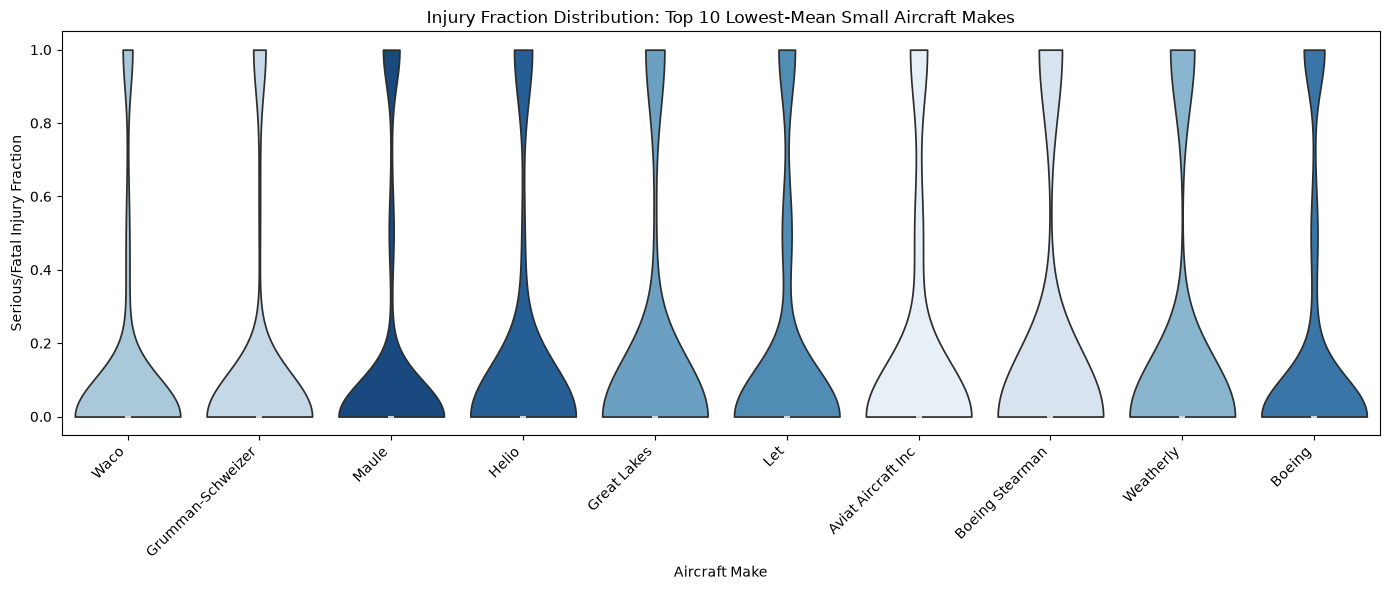

Summary of top 10 small makes with lowest mean injury fraction:


,Make,n,mean_fraction
0,Waco,138,0.102657
1,Grumman-Schweizer,127,0.111549
2,Maule,570,0.153889
3,Helio,107,0.156684
4,Great Lakes,60,0.158333
5,Let,136,0.161765
6,Aviat Aircraft Inc,77,0.162338
7,Boeing Stearman,50,0.180000
8,Weatherly,86,0.186047
9,Boeing,515,0.186447


In [26]:
# Finding the 10 smallest aircraft makes with the lowest average injury fraction 
small_makes = (
    df.loc[df['aircraft_size'] == 'Small (<20 occupants)']
      .groupby('Make')
      .agg(n=('injury_fraction', 'count'),
           mean_fraction=('injury_fraction', 'mean'))
      .query('n >= 50')
      .nsmallest(10, 'mean_fraction')
      .reset_index()
)

# Filtering teh dataset for plotting these specific makes
plot_data = df.loc[
    (df['aircraft_size'] == 'Small (<20 occupants)') &
    (df['Make'].isin(small_makes['Make'])) &
    df['injury_fraction'].notna()
]

# Creating a violin plot to show the distribution of injury fractions
plt.figure(figsize=(14, 6))
sns.violinplot(
    data=plot_data, 
    x='Make', 
    y='injury_fraction', 
    hue='Make',
    order=small_makes['Make'], 
    cut=0, 
    palette='Blues_r',
    legend=False
)

plt.xticks(rotation=45, ha='right')
plt.title("Injury Fraction Distribution: Top 10 Lowest-Mean Small Aircraft Makes")
plt.ylabel("Serious/Fatal Injury Fraction")
plt.xlabel("Aircraft Make")
plt.tight_layout()
plt.show()

print("Summary of top 10 small makes with lowest mean injury fraction:")
display(small_makes)

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

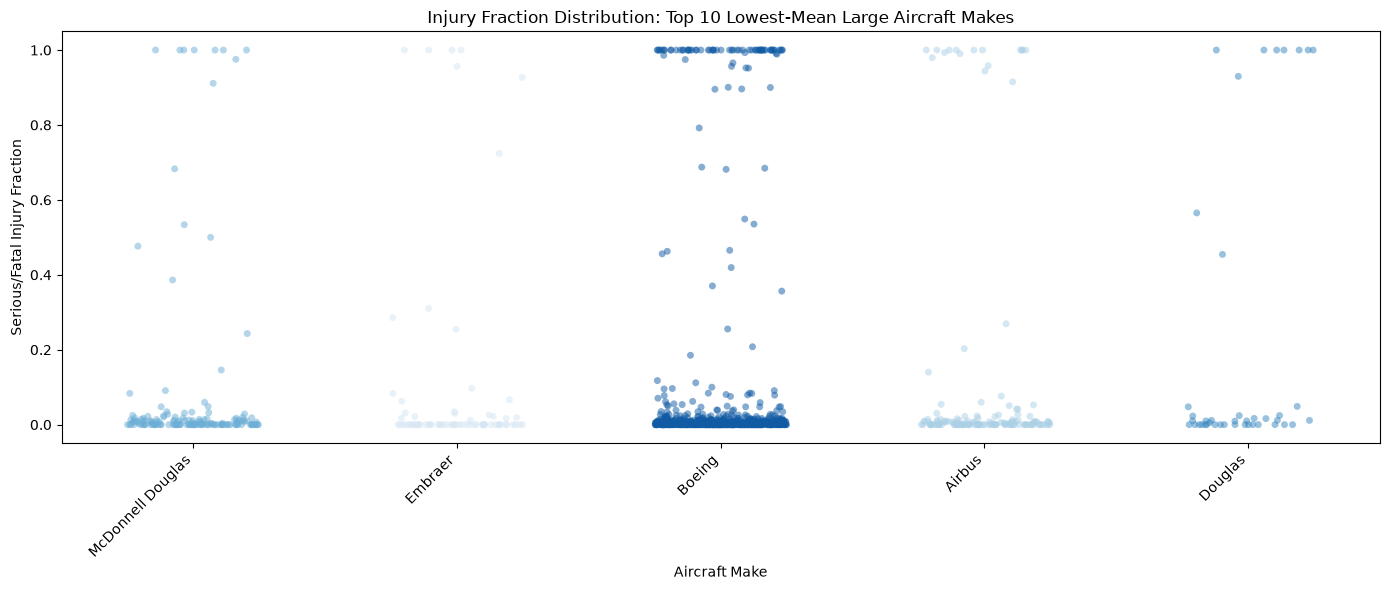

Summary of top 10 large makes with lowest mean injury fraction:


,Make,n,mean_fraction
0,McDonnell Douglas,155,0.083765
1,Embraer,72,0.111087
2,Boeing,712,0.114563
3,Airbus,144,0.119909
4,Douglas,42,0.219753


In [27]:
# Finding the 10 largest aircraft makes with the lowest average injury fraction 
large_makes = (
    df.loc[df['aircraft_size'] == 'Large (20+ occupants)']
      .groupby('Make')
      .agg(n=('injury_fraction', 'count'),
           mean_fraction=('injury_fraction', 'mean'))
      .query('n >= 30')
      .nsmallest(10, 'mean_fraction')
      .reset_index()
)

# Filtering the dataset for plotting these specific large makes
plot_data = df.loc[
    (df['aircraft_size'] == 'Large (20+ occupants)') &
    (df['Make'].isin(large_makes['Make'])) &
    df['injury_fraction'].notna()
]

# Creating strip plot to visualize injury fractions for large aircraft
plt.figure(figsize=(14, 6))
sns.stripplot(
    data=plot_data, 
    x='Make', 
    y='injury_fraction', 
    hue='Make',
    order=large_makes['Make'], 
    jitter=0.25, 
    alpha=0.5, 
    size=5,
    legend=False,
    palette='Blues_r'
)

plt.xticks(rotation=45, ha='right')
plt.title("Injury Fraction Distribution: Top 10 Lowest-Mean Large Aircraft Makes")
plt.ylabel("Serious/Fatal Injury Fraction")
plt.xlabel("Aircraft Make")
plt.tight_layout()
plt.show()

print("Summary of top 10 large makes with lowest mean injury fraction:")
display(large_makes)

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

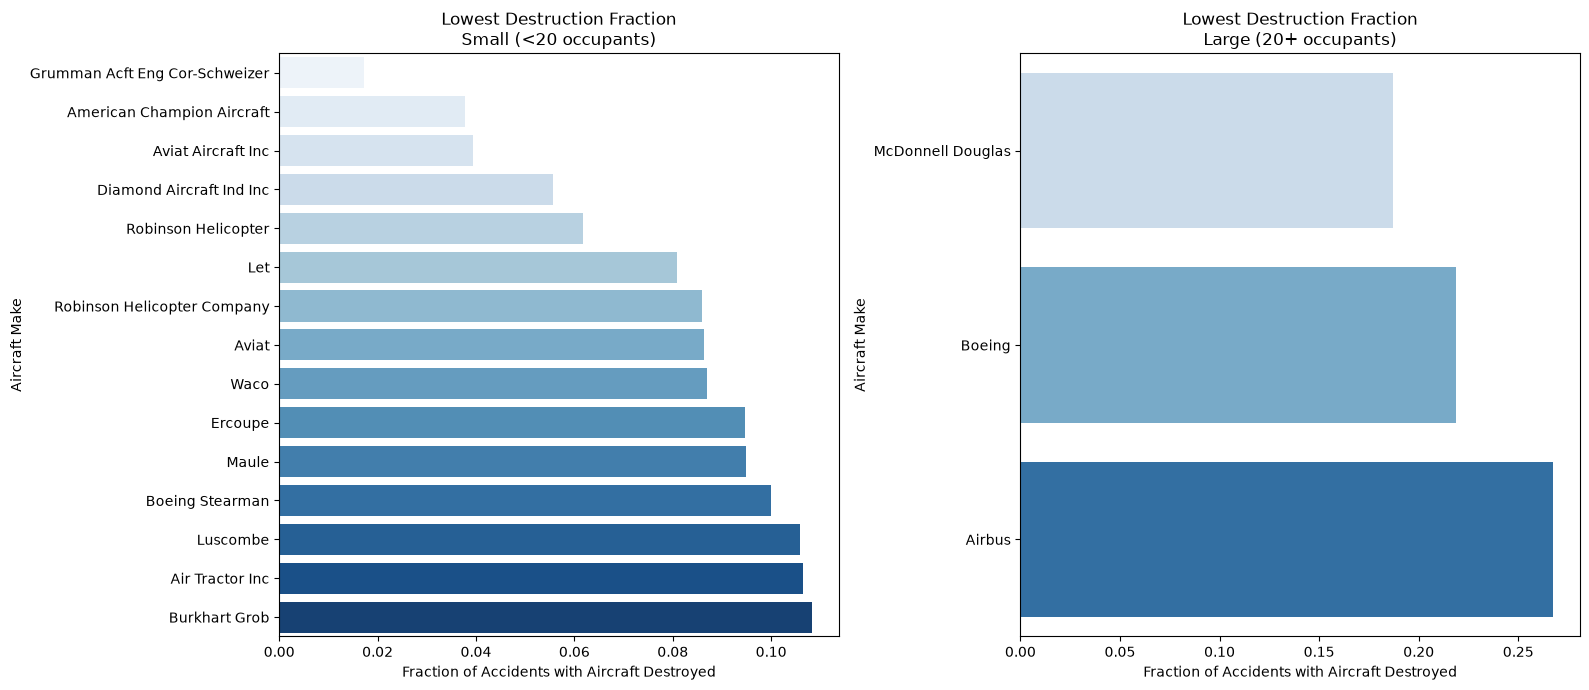

Top makes by lowest aircraft destruction fraction:


,aircraft_size,Make,n,destroyed_fraction
2,Large (20+ occupants),McDonnell Douglas,107,0.186916
1,Large (20+ occupants),Boeing,384,0.218750
0,Large (20+ occupants),Airbus,71,0.267606
41,Small (<20 occupants),Grumman Acft Eng Cor-Schweizer,58,0.017241
11,Small (<20 occupants),American Champion Aircraft,53,0.037736
13,Small (<20 occupants),Aviat Aircraft Inc,76,0.039474
29,Small (<20 occupants),Diamond Aircraft Ind Inc,72,0.055556
68,Small (<20 occupants),Robinson Helicopter,227,0.061674
51,Small (<20 occupants),Let,136,0.080882
69,Small (<20 occupants),Robinson Helicopter Company,186,0.086022


In [28]:
# calculate aircraft destruction fraction by size group and make (min 50 records)
damage_summary = (
    df.dropna(subset=['aircraft_size', 'aircraft_destroyed'])
      .groupby(['aircraft_size', 'Make'])
      .agg(
          n=('aircraft_destroyed', 'size'), 
          destroyed_fraction=('aircraft_destroyed', 'mean')
      )
      .query('n >= 50')
      .reset_index()
)

# plot the 15 makes with the lowest destruction fraction for small and large aircraft
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, group in zip(axes, ['Small (<20 occupants)', 'Large (20+ occupants)']):
    sub = damage_summary[damage_summary['aircraft_size'] == group].nsmallest(15, 'destroyed_fraction')
    
    sns.barplot(
        data=sub, 
        x='destroyed_fraction', 
        y='Make', 
        hue='Make',
        ax=ax, 
        palette='Blues',
        legend=False
    )
    
    ax.set_title(f"Lowest Destruction Fraction\n{group}")
    ax.set_xlabel("Fraction of Accidents with Aircraft Destroyed")
    ax.set_ylabel("Aircraft Make")

plt.tight_layout()
plt.show()

# display the summary table
print("Top makes by lowest aircraft destruction fraction:")
display(
    damage_summary.sort_values(['aircraft_size', 'destroyed_fraction'])
                  .groupby('aircraft_size')
                  .head(15)
)

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

An analysis of the accident data presented in the reports reveals that the safety performance, in terms of both human injury and property damage, differs considerably between manufacturers.
In the case of planes carrying fewer than 20 people, Waco and Maule aircraft are associated with fewer serious, non-fatal injuries and aircraft destruction instances with sufficient confidence. 
As for aircraft with a capacity of more than 20 people, McDonnell Douglas aircraft appear to be safer in terms of both human injury and property damage in comparison to Boeing and Airbus planes.
Nevertheless, it is hard to claim that one type of aircraft is significantly safer than the others based on the provided data. For one thing, the number of severe incidents for each manufacturer varies substantially. For another, the reports reflect recorded accidents and not the total number of flights operated by each type of aircraft. 
Therefore, it is essential to rely on the presented information in combination with other data, such as the aircraft’s age and the conditions under which it is operated.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

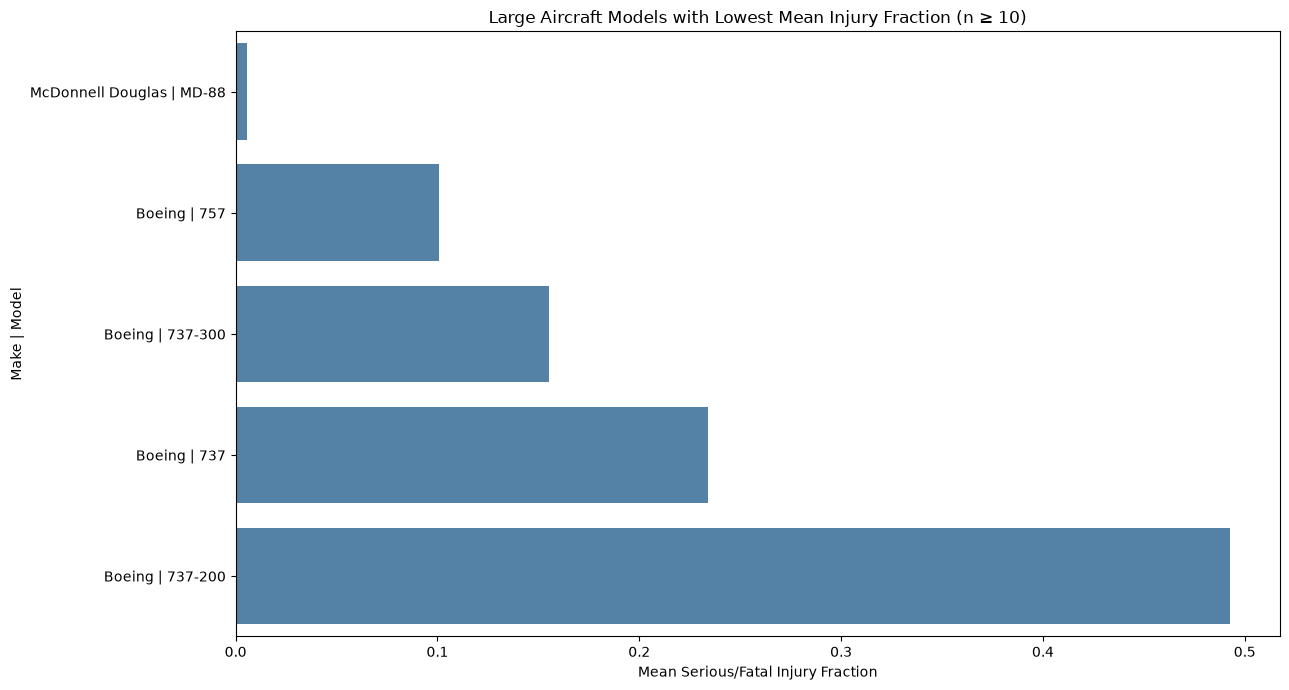

Summary of top large aircraft models:


,aircraft_size,Make.Model,Make,Model,n,mean_injury_fraction,median_injury_fraction,destruction_fraction
4,Large (20+ occupants),McDonnell Douglas | MD-88,McDonnell Douglas,MD-88,10,0.005520,0.000000,0.000000
3,Large (20+ occupants),Boeing | 757,Boeing,757,10,0.100816,0.000000,0.200000
2,Large (20+ occupants),Boeing | 737-300,Boeing,737-300,17,0.155150,0.000000,0.235294
0,Large (20+ occupants),Boeing | 737,Boeing,737,56,0.234235,0.000000,0.196429
1,Large (20+ occupants),Boeing | 737-200,Boeing,737-200,20,0.492823,0.431334,0.600000


In [29]:
# Calculating the model-level summary statistics (min 10 observations per model)
model_summary = (
    df.dropna(subset=['Make.Model', 'aircraft_size', 'injury_fraction', 'aircraft_destroyed'])
      .groupby(['aircraft_size', 'Make.Model', 'Make', 'Model'])
      .agg(
          n=('injury_fraction', 'count'),
          mean_injury_fraction=('injury_fraction', 'mean'),
          median_injury_fraction=('injury_fraction', 'median'),
          destruction_fraction=('aircraft_destroyed', 'mean')
      )
      .query('n >= 10')
      .reset_index()
)

# Filtering for large aircraft models with the lowest mean serious/fatal injury fraction
large_models = (
    model_summary[model_summary['aircraft_size'] == 'Large (20+ occupants)']
    .nsmallest(15, 'mean_injury_fraction')
    .sort_values('mean_injury_fraction', ascending=True)
)

# Plotting the results
plt.figure(figsize=(13, 7))
sns.barplot(
    data=large_models, 
    x='mean_injury_fraction', 
    y='Make.Model', 
    color='steelblue'
)

plt.title("Large Aircraft Models with Lowest Mean Injury Fraction (n ≥ 10)")
plt.xlabel("Mean Serious/Fatal Injury Fraction")
plt.ylabel("Make | Model")
plt.tight_layout()
plt.show()

# Displaying the summary table
print("Summary of top large aircraft models:")
display(large_models)

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

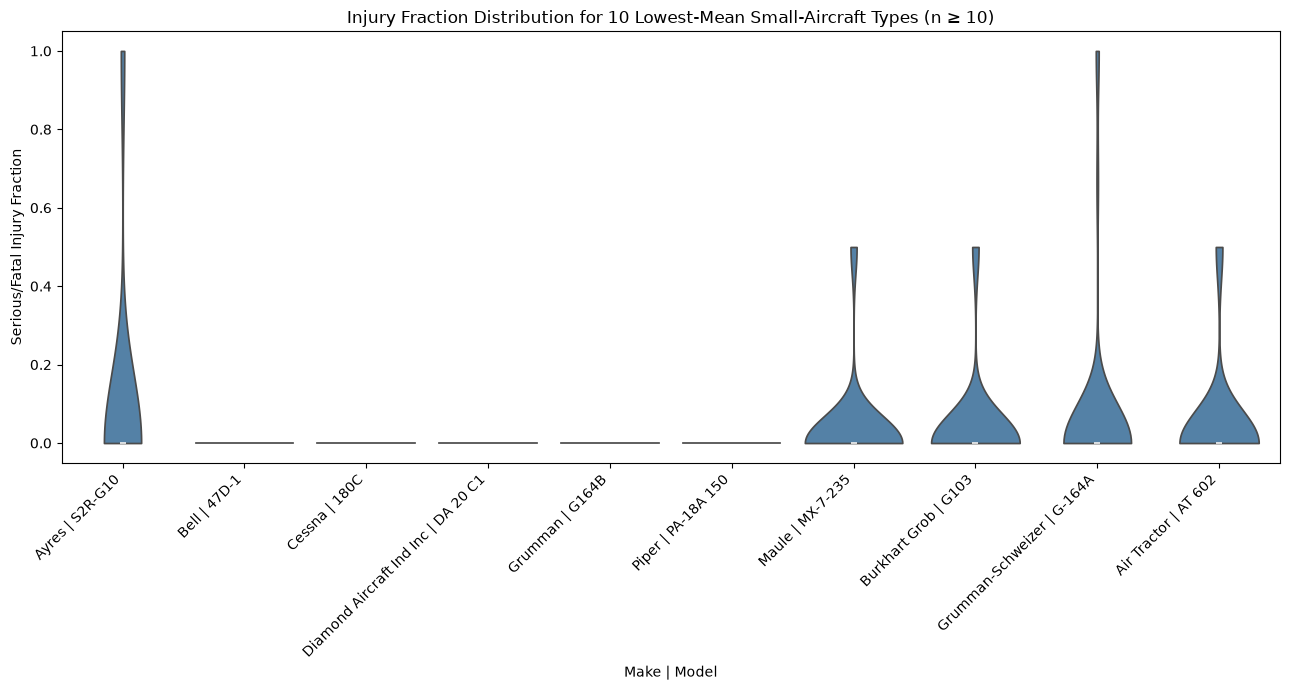

Summary of top small aircraft models:


,aircraft_size,Make.Model,Make,Model,n,mean_injury_fraction,median_injury_fraction,destruction_fraction
74,Small (<20 occupants),Ayres | S2R-G10,Ayres,S2R-G10,11,0.000000,0.0,0.181818
202,Small (<20 occupants),Bell | 47D-1,Bell,47D-1,10,0.000000,0.0,0.000000
298,Small (<20 occupants),Cessna | 180C,Cessna,180C,14,0.000000,0.0,0.071429
493,Small (<20 occupants),Diamond Aircraft Ind Inc | DA 20 C1,Diamond Aircraft Ind Inc,DA 20 C1,11,0.000000,0.0,0.000000
545,Small (<20 occupants),Grumman | G164B,Grumman,G164B,16,0.000000,0.0,0.062500
673,Small (<20 occupants),Piper | PA-18A 150,Piper,PA-18A 150,12,0.000000,0.0,0.000000
595,Small (<20 occupants),Maule | MX-7-235,Maule,MX-7-235,17,0.029412,0.0,0.000000
243,Small (<20 occupants),Burkhart Grob | G103,Burkhart Grob,G103,15,0.033333,0.0,0.000000
546,Small (<20 occupants),Grumman-Schweizer | G-164A,Grumman-Schweizer,G-164A,49,0.034014,0.0,0.163265
45,Small (<20 occupants),Air Tractor | AT 602,Air Tractor,AT 602,13,0.038462,0.0,0.000000


In [30]:
# Finding the 10 small aircraft models with the lowest mean injury fraction (min 10 records)
small_models = (
    model_summary[model_summary['aircraft_size'] == 'Small (<20 occupants)']
    .nsmallest(10, 'mean_injury_fraction')
)

# Filtering the raw dataset for these specific small models
small_model_rows = df.loc[
    (df['aircraft_size'] == 'Small (<20 occupants)') &
    (df['Make.Model'].isin(small_models['Make.Model'])) &
    df['injury_fraction'].notna()
]

# Plotting the violinplot
plt.figure(figsize=(13, 7))
sns.violinplot(
    data=small_model_rows, 
    x='Make.Model', 
    y='injury_fraction', 
    order=small_models['Make.Model'], 
    cut=0,
    color='steelblue'
)

plt.xticks(rotation=45, ha='right')
plt.title("Injury Fraction Distribution for 10 Lowest-Mean Small-Aircraft Types (n ≥ 10)")
plt.xlabel("Make | Model")
plt.ylabel("Serious/Fatal Injury Fraction")
plt.tight_layout()
plt.show()

# Displaying the summary table
print("Summary of top small aircraft models:")
display(small_models.sort_values('mean_injury_fraction'))

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

The results of the analysis can be used to identify airplane models that should be studied further.
They show that the mean fraction of passengers seriously or fatally injured can vary significantly for both small- and large-sized airplanes. 
For the latter, the distribution plots also show that the mean injury fraction is not always typical for a given model due to the possible presence of outliers. The results are applicable because the study analyzed accident data, which is relevant to the objective, but the injury fractions should be regarded with caution due to the possibility of missing information. 
In addition, the data set contains information on individual flights and not all possible flights.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

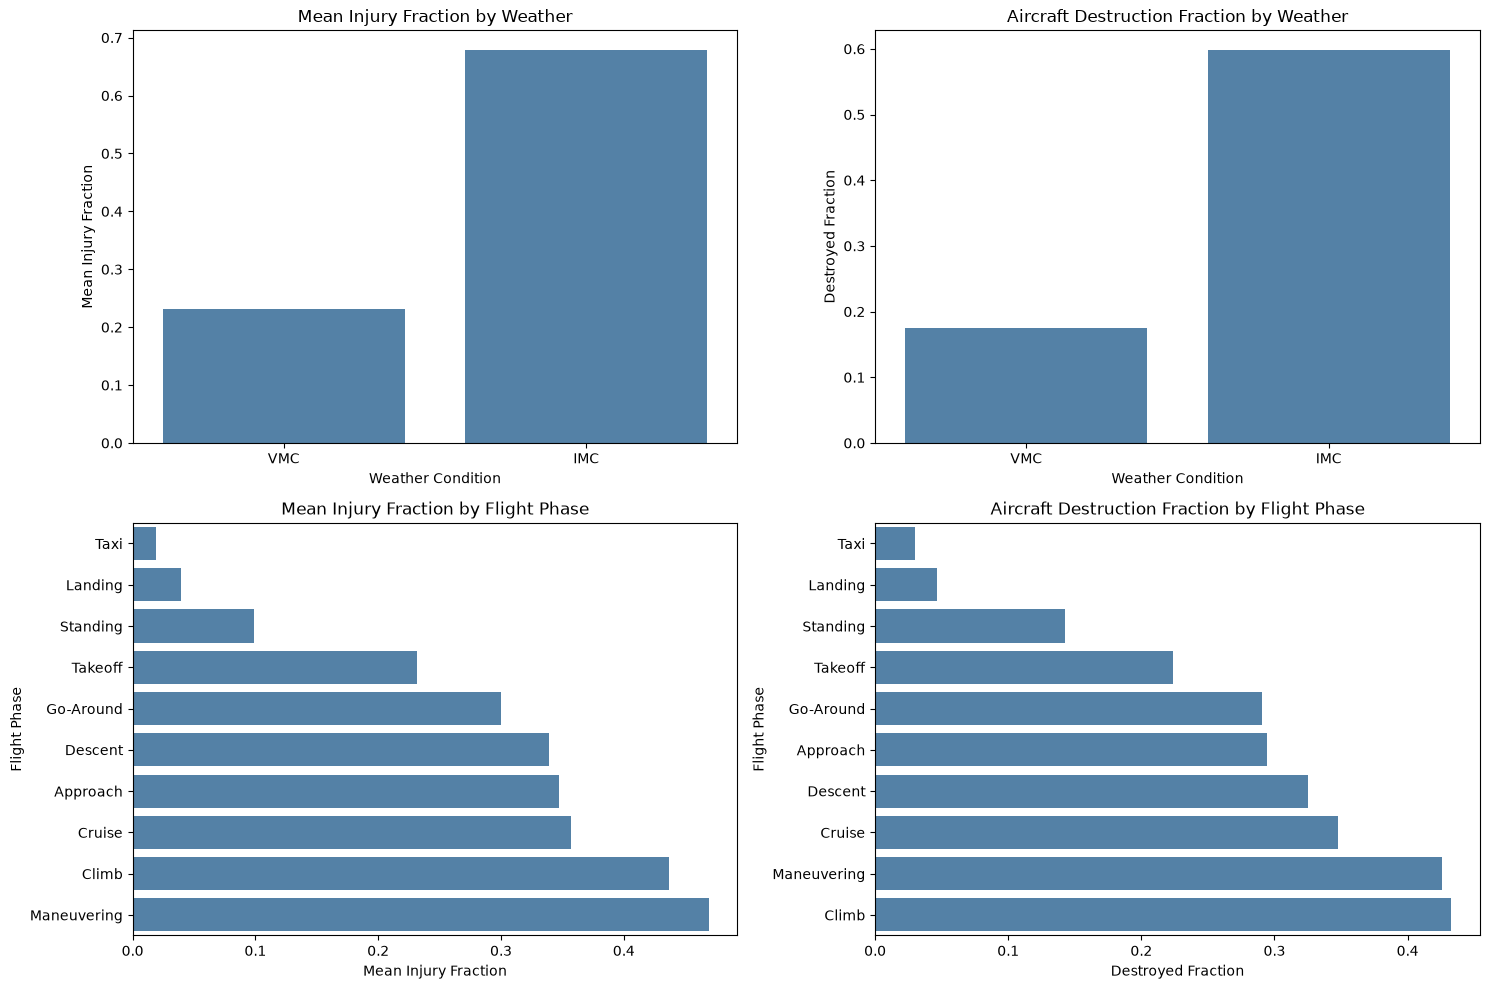

Weather Condition Summary:


,Weather.Condition,n,mean_injury_fraction,median_injury_fraction,destroyed_fraction
0,VMC,58432,0.232055,0.0,0.175127
1,IMC,4944,0.678722,1.0,0.598301



Broad Phase of Flight Summary:


,Broad.phase.of.flight,n,mean_injury_fraction,median_injury_fraction,destroyed_fraction
3,Maneuvering,6281,0.469129,0.0,0.425569
5,Climb,1472,0.437087,0.0,0.432745
2,Cruise,8003,0.357177,0.0,0.347620
4,Approach,5041,0.347054,0.0,0.294386
7,Descent,1387,0.339486,0.0,0.325162
8,Go-Around,1176,0.300093,0.0,0.290816
1,Takeoff,9511,0.231738,0.0,0.224056
9,Standing,603,0.098820,0.0,0.142620
0,Landing,12668,0.039561,0.0,0.046574
6,Taxi,1463,0.019243,0.0,0.030075



Interpretation: Weather and flight phase associations are descriptive and can be confounded by aircraft type, mission, or reporting practices.


In [31]:
# Defining the helper function to aggregate metrics by factor (min 100 observations)
def factor_summary(data, factor, min_n=100):
    return (
        data.dropna(subset=[factor, 'injury_fraction', 'aircraft_destroyed'])
            .groupby(factor)
            .agg(
                n=('Make', 'size'),
                mean_injury_fraction=('injury_fraction', 'mean'),
                median_injury_fraction=('injury_fraction', 'median'),
                destroyed_fraction=('aircraft_destroyed', 'mean')
            )
            .query('n >= @min_n')
            .sort_values('n', ascending=False)
            .reset_index()
    )

# Generating summaries for weather condition and flight phase
weather_summary = factor_summary(df, 'Weather.Condition', min_n=100)
phase_summary = factor_summary(df, 'Broad.phase.of.flight', min_n=100)

# Plotting weather and flight phase comparisons
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.barplot(data=weather_summary, x='Weather.Condition', y='mean_injury_fraction', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title("Mean Injury Fraction by Weather")
axes[0, 0].set(xlabel="Weather Condition", ylabel="Mean Injury Fraction")

sns.barplot(data=weather_summary, x='Weather.Condition', y='destroyed_fraction', ax=axes[0, 1], color='steelblue')
axes[0, 1].set_title("Aircraft Destruction Fraction by Weather")
axes[0, 1].set(xlabel="Weather Condition", ylabel="Destroyed Fraction")

phase_injury = phase_summary.sort_values('mean_injury_fraction', ascending=True)
sns.barplot(data=phase_injury, x='mean_injury_fraction', y='Broad.phase.of.flight', ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title("Mean Injury Fraction by Flight Phase")
axes[1, 0].set(xlabel="Mean Injury Fraction", ylabel="Flight Phase")

phase_damage = phase_summary.sort_values('destroyed_fraction', ascending=True)
sns.barplot(data=phase_damage, x='destroyed_fraction', y='Broad.phase.of.flight', ax=axes[1, 1], color='steelblue')
axes[1, 1].set_title("Aircraft Destruction Fraction by Flight Phase")
axes[1, 1].set(xlabel="Destroyed Fraction", ylabel="Flight Phase")

plt.tight_layout()
plt.show()

# Displaying the summary tables and interpretation note
print("Weather Condition Summary:")
display(weather_summary)

print("\nBroad Phase of Flight Summary:")
display(phase_summary.sort_values('mean_injury_fraction', ascending=False))

print("\nInterpretation: Weather and flight phase associations are descriptive and can be confounded by aircraft type, mission, or reporting practices.")